## Problema - Organización y búsqueda de productos en una tienda

**Instrucción:** completa esta plantilla con tu diseño y desarrollo. Evita incluir soluciones generadas automáticamente.



In [ ]:
# @title Ingrese datos
nombre_estudiante = "Gabriel Baron, Juan Pablo Guerrero, Anderson Varela y Julian Sanchez"
carnet =   1000,     ,1000     ,1000   , 1000113984


## 1) Descripción del problema **[1 pts]**
Una tienda requiere optimizar la consulta y gestión de su inventario mediante la implementación manual de una Tabla Hash. Para evitar recorrer listas completas, los productos se almacenarán utilizando su código numérico como llave, aplicando una función hash $h(código) = código \pmod m$ y resolviendo las colisiones mediante encadenamiento.

ENTRADAS:

$m$: Tamaño de la tabla hash (número entero).   

$n$: Cantidad de productos que se desean registrar inicialmente (número entero).

Datos de los Productos (por cada producto a registrar):

Código: Identificador único numérico (utilizado como llave).

Nombre: Descripción textual del producto (ej. Arroz, Leche).

Precio: Valor monetario del producto (número decimal o entero).

Cantidad disponible: Unidades en stock (número entero).

Operaciones de Consulta y Modificación:

Búsqueda: El código numérico del producto que se desea consultar.

Eliminación: El código numérico del producto que se desea eliminar del inventario.

Actualización: El código del producto a modificar y el valor de la nueva cantidad disponible.

SALIDAS

Visualización de la Tabla Hash:

Representación estructurada de la tabla desde el índice $0$ hasta el $m-1$.

Listado de productos por índice. En caso de colisión en una misma posición, se muestran todos los elementos encadenados (ej. Índice 3: 101 - Arroz -> 108 - Huevos).

Indicación de casillas vacías (Vacío).

Resultados de Operaciones:Búsqueda Exitosa: 

Muestra los detalles completos del producto (Código, Nombre, Precio y Cantidad disponible).

Búsqueda Fallida / No Encontrada: Mensaje de alerta indicando que el producto no está registrado (ej. "El producto no está registrado" o "No se encontró el producto").

Confirmación de Actualización: Mensaje de éxito junto con el estado actualizado del producto (ej. "Inventario actualizado correctamente. Arroz - 35 unidades").

Estado de Eliminación: Visualización parcial o total de la tabla reflejando la remoción del elemento seleccionado.

## 2) Requerimientos **[2 pts]**

Lista requerimientos.

FUNCIONALES.
01. El sistema debe permitir al usuario ingresar el tamaño $m$ de la tabla y generar una estructura de tamaño $m$ inicializada completamente vacía.
02. El sistema debe calcular automáticamente la posición de almacenamiento de cada producto utilizando la función matemática $h(código) = código \pmod m$.
03. El sistema debe permitir registrar una cantidad $n$ de productos solicitando sus atributos: código (llave), nombre, precio y cantidad disponible.
04. El sistema debe resolver de forma automática las colisiones mediante encadenamiento, permitiendo almacenar múltiples productos en una misma posición de la tabla.
05. El sistema debe impedir el registro de dos productos que compartan exactamente el mismo código numérico.
06. El sistema debe permitir consultar un producto ingresando su código, aplicando primero la función hash para acceder directamente a la posición sin recorrer toda la tabla.
07. El sistema debe permitir eliminar un producto específico a partir de su código, ubicando su posición con la función hash y removiéndolo únicamente del encadenamiento correspondiente.
08. El sistema debe permitir buscar un producto por su código y modificar exclusivamente su atributo de cantidad disponible.
09. El sistema debe permitir mostrar por pantalla el estado completo de la estructura, visualizando claramente las posiciones vacías y todos los elementos encadenados.

NO FUNCIONALES

10. La estructura de datos de la Tabla Hash y el mecanismo de encadenamiento deben ser implementados manualmente, sin depender de librerías externas que automaticen tablas hash nativas para la lógica principal.

11. Las operaciones de búsqueda y eliminación deben tener un tiempo de acceso directo optimizado a través de la función hash, evitando recorridos lineales completos de toda la tabla.

12. La interacción con el programa debe realizarse mediante mensajes claros, entradas estructuradas y salidas formateadas en consola o celdas de un Notebook.

13. El desarrollo debe entregarse en un Notebook ejecutado y documentado, evidenciando todas las pruebas y validaciones requeridas.


## 3) Historias de usuario **[2 pts]**
Escribe 3–5 historias de usuario con el formato visto en clase:
Incluye criterios de aceptación.


## 4) Diagramas de flujo **[5 pts]**
Incluye el diagrama que muestre el proceso general

Adjunta imagen y descríbelo claramente.


### 5) Análisis de complejidad **[15 pts]**
Incluye:
- Justificación
- Función T[n]
- Mejor y peor caso con gráfica


## 6) Código funcional **[15 pts]**
Incluye tu implementación completa.

No pegues código incompleto; debe ser ejecutable.


In [1]:

# ==========================================
# TABLA HASH PARA INVENTARIO DE PRODUCTOS
# ==========================================

# Funcion para leer numeros enteros
def leer_entero(mensaje, permitir_cero=False):
    while True:
        dato = input(mensaje)

        if dato == "0" and permitir_cero:
            return 0

        try:
            return int(dato)
        except ValueError:
            print("Error: debes ingresar un numero entero.")
            print("Escribe 0 para regresar al menu.")


# Funcion para leer precios
def leer_precio(mensaje):
    while True:
        dato = input(mensaje)

        if dato == "0":
            return 0

        try:
            precio = float(dato)

            if precio < 0:
                print("El precio no puede ser negativo.")
            else:
                return precio

        except ValueError:
            print("Error: ingresa un precio valido.")
            print("Escribe 0 para regresar al menu.")


# Crear la tabla hash
while True:
    try:
        m = int(input("Ingrese el tamano de la tabla hash: "))

        if m > 0:
            break

        print("El tamano debe ser mayor que cero.")

    except ValueError:
        print("Error: ingresa un numero entero valido.")

tabla = []

for i in range(m):
    tabla.append([])


# Funcion hash
def funcion_hash(codigo):
    return codigo % m


# Buscar producto
def buscar_producto(codigo):
    indice = funcion_hash(codigo)

    for producto in tabla[indice]:
        if producto["codigo"] == codigo:
            return producto

    return None


# Insertar producto
def insertar_producto():
    print("\n--- REGISTRAR PRODUCTO ---")
    print("Escribe 0 en un campo numerico para regresar al menu.")

    codigo = leer_entero("Codigo del producto: ", True)

    if codigo == 0:
        print("Regresando al menu principal...")
        return

    if codigo < 0:
        print("El codigo no puede ser negativo.")
        return

    if buscar_producto(codigo) is not None:
        print("Ya existe un producto con ese codigo.")
        return

    nombre = input("Nombre del producto: ")

    if nombre.strip() == "" or nombre == "0":
        print("Registro cancelado. Regresando al menu.")
        return

    precio = leer_precio("Precio: ")

    if precio == 0:
        print("Registro cancelado. Regresando al menu.")
        return

    cantidad = leer_entero("Cantidad disponible: ", True)

    if cantidad == 0:
        print("Registro cancelado. Regresando al menu.")
        return

    if cantidad < 0:
        print("La cantidad no puede ser negativa.")
        return

    producto = {
        "codigo": codigo,
        "nombre": nombre,
        "precio": precio,
        "cantidad": cantidad
    }

    indice = funcion_hash(codigo)
    tabla[indice].append(producto)

    print("\nProducto registrado correctamente.")
    print("Posicion asignada:", indice)


# Consultar producto
def consultar_producto():
    print("\n--- BUSCAR PRODUCTO ---")

    codigo = leer_entero(
        "Codigo del producto (0 para regresar): ", True
    )

    if codigo == 0:
        return

    if codigo < 0:
        print("El codigo no puede ser negativo.")
        return

    indice = funcion_hash(codigo)
    producto = buscar_producto(codigo)

    print("Posicion calculada:", indice)

    if producto is not None:
        print("\nPRODUCTO ENCONTRADO")
        print("Codigo:", producto["codigo"])
        print("Nombre:", producto["nombre"])
        print("Precio: $", format(producto["precio"], ",.2f"))
        print("Cantidad disponible:", producto["cantidad"])
    else:
        print("El producto no esta registrado.")


# Eliminar producto
def eliminar_producto():
    print("\n--- ELIMINAR PRODUCTO ---")

    codigo = leer_entero(
        "Codigo del producto (0 para regresar): ", True
    )

    if codigo == 0:
        return

    if codigo < 0:
        print("El codigo no puede ser negativo.")
        return

    indice = funcion_hash(codigo)

    for producto in tabla[indice]:
        if producto["codigo"] == codigo:
            print("Producto:", producto["nombre"])
            confirmar = input("Confirmar eliminacion? (s/n): ")

            if confirmar.lower() == "s":
                tabla[indice].remove(producto)
                print("Producto eliminado correctamente.")
            else:
                print("Eliminacion cancelada.")

            return

    print("No se encontro el producto.")


# Actualizar inventario
def actualizar_inventario():
    print("\n--- ACTUALIZAR INVENTARIO ---")

    codigo = leer_entero(
        "Codigo del producto (0 para regresar): ", True
    )

    if codigo == 0:
        return

    if codigo < 0:
        print("El codigo no puede ser negativo.")
        return

    producto = buscar_producto(codigo)

    if producto is None:
        print("El producto no esta registrado.")
        return

    print("Producto:", producto["nombre"])
    print("Cantidad actual:", producto["cantidad"])

    nueva_cantidad = leer_entero(
        "Nueva cantidad (0 para regresar): ", True
    )

    if nueva_cantidad == 0:
        print("Actualizacion cancelada.")
        return

    if nueva_cantidad < 0:
        print("La cantidad no puede ser negativa.")
        return

    producto["cantidad"] = nueva_cantidad

    print("Inventario actualizado correctamente.")
    print(producto["nombre"], "-", nueva_cantidad, "unidades")


# Mostrar tabla hash
def mostrar_tabla():
    print("\n==========================================")
    print("                 TABLA HASH")
    print("==========================================")

    for i in range(m):
        print(str(i) + " -> ", end="")

        if len(tabla[i]) == 0:
            print("Vacio")
        else:
            for producto in tabla[i]:
                print(
                    producto["codigo"], "-",
                    producto["nombre"],
                    "- $", format(producto["precio"], ",.2f"),
                    "-", producto["cantidad"], "unidades",
                    end=" -> "
                )

            print("FIN")

    print("==========================================")


# Registrar productos iniciales
def registro_inicial():
    print("\n--- REGISTRO INICIAL ---")
    print("Escribe 0 para regresar al menu.")

    n = leer_entero("Cuantos productos desea registrar?: ", True)

    if n <= 0:
        return

    for i in range(n):
        print("\nProducto", i + 1, "de", n)
        insertar_producto()


# Menu principal
while True:
    print("\n========== MENU INVENTARIO ==========")
    print("1. Insertar producto")
    print("2. Buscar producto")
    print("3. Eliminar producto")
    print("4. Actualizar inventario")
    print("5. Mostrar tabla hash")
    print("6. Registrar varios productos")
    print("7. Salir")
    print("=====================================")

    try:
        opcion = int(input("Seleccione una opcion: "))
    except ValueError:
        print("Error: escribe un numero del 1 al 7.")
        continue

    if opcion == 1:
        insertar_producto()

    elif opcion == 2:
        consultar_producto()

    elif opcion == 3:
        eliminar_producto()

    elif opcion == 4:
        actualizar_inventario()

    elif opcion == 5:
        mostrar_tabla()

    elif opcion == 6:
        registro_inicial()

    elif opcion == 7:
        print("Programa finalizado.")
        break

    else:
        print("Opcion no valida. Intenta nuevamente.")




========== MENU INVENTARIO ==========
1. Insertar producto
2. Buscar producto
3. Eliminar producto
4. Actualizar inventario
5. Mostrar tabla hash
6. Registrar varios productos
7. Salir

--- REGISTRAR PRODUCTO ---
Escribe 0 en un campo numerico para regresar al menu.

Producto registrado correctamente.
Posicion asignada: 1

========== MENU INVENTARIO ==========
1. Insertar producto
2. Buscar producto
3. Eliminar producto
4. Actualizar inventario
5. Mostrar tabla hash
6. Registrar varios productos
7. Salir

--- REGISTRAR PRODUCTO ---
Escribe 0 en un campo numerico para regresar al menu.

Producto registrado correctamente.
Posicion asignada: 0

========== MENU INVENTARIO ==========
1. Insertar producto
2. Buscar producto
3. Eliminar producto
4. Actualizar inventario
5. Mostrar tabla hash
6. Registrar varios productos
7. Salir

                 TABLA HASH
0 -> 45 - Leche - $ 21.00 - 25 unidades -> FIN
1 -> 1 - 02 - $ 3.00 - 4 unidades -> FIN
2 -> Vacio
3 -> Vacio
4 -> Vacio

========== ME

## 7) Tests aplicados **[15 pts]**

In [2]:
# ==========================================
#      PRUEBAS DE ENUNCIADO - TABLA HASH
# ==========================================
print("=" * 60)
print("      EJECUTANDO PRUEBAS DE ENUNCIADO (TABLA HASH) ")
print("=" * 60)

# 1. Configuración de la tabla con el tamaño del enunciado (m = 7)
m = 7
tabla = [[] for _ in range(m)]

# 2. Pruebas de la Función Hash
assert funcion_hash(101) == 3, f"Error: El hash de 101 debería ser 3, se obtuvo {funcion_hash(101)}"
assert funcion_hash(205) == 2, f"Error: El hash de 205 debería ser 2, se obtuvo {funcion_hash(205)}"
assert funcion_hash(312) == 4, f"Error: El hash de 312 debería ser 4, se obtuvo {funcion_hash(312)}"
assert funcion_hash(108) == 3, f"Error: El hash de 108 debería ser 3 (colisión), se obtuvo {funcion_hash(108)}"

# 3. Inserción de productos de prueba (incluyendo la colisión en el índice 3)
productos_prueba = [
    {"codigo": 101, "nombre": "Arroz", "precio": 4500.0, "cantidad": 20},
    {"codigo": 205, "nombre": "Leche", "precio": 3800.0, "cantidad": 15},
    {"codigo": 312, "nombre": "Café", "precio": 12000.0, "cantidad": 10},
    {"codigo": 108, "nombre": "Huevos", "precio": 16000.0, "cantidad": 12}
]

for p in productos_prueba:
    indice = funcion_hash(p["codigo"])
    tabla[indice].append(p)

# 4. Pruebas de Colisión por Encadenamiento
assert len(tabla[3]) == 2, f"Error: El índice 3 debería tener 2 elementos por colisión, tiene {len(tabla[3])}"
assert tabla[3][0]["codigo"] == 101, "Error: El primer elemento del índice 3 debe ser 101"
assert tabla[3][1]["codigo"] == 108, "Error: El segundo elemento del índice 3 debe ser 108 (colisión)"

# 5. Pruebas de Búsqueda (Exitosa e Inexistente)
prod_encontrado = buscar_producto(108)
assert prod_encontrado is not None, "Error: Debería encontrar el producto con código 108"
assert prod_encontrado["nombre"] == "Huevos", f"Error: Se esperaba 'Huevos', se obtuvo {prod_encontrado['nombre']}"

prod_inexistente = buscar_producto(999)
assert prod_inexistente is None, "Error: Un código inexistente debería retornar None"

# 6. Pruebas de Actualización de Inventario
prod_a_actualizar = buscar_producto(101)
prod_a_actualizar["cantidad"] = 35  # Simulando la actualización de cantidad
assert buscar_producto(101)["cantidad"] == 35, "Error: La cantidad disponible no se actualizó correctamente"

# 7. Pruebas de Eliminación
# Eliminamos el producto 108 del encadenamiento en el índice 3
idx_eliminar = funcion_hash(108)
tabla[idx_eliminar] = [prod for prod in tabla[idx_eliminar] if prod["codigo"] != 108]

assert buscar_producto(108) is None, "Error: El producto 108 debió haber sido eliminado"
assert len(tabla[3]) == 1, f"Error: Tras eliminar el 108, el índice 3 debería tener 1 solo elemento, tiene {len(tabla[3])}"

print("\n ¡Todas las pruebas con assert de la Tabla Hash pasaron exitosamente sin errores!")
print("\nMostrando estado final de la estructura:")
mostrar_tabla()


      EJECUTANDO PRUEBAS DE ENUNCIADO (TABLA HASH) 

 ¡Todas las pruebas con assert de la Tabla Hash pasaron exitosamente sin errores!

Mostrando estado final de la estructura:

                 TABLA HASH
0 -> Vacio
1 -> Vacio
2 -> 205 - Leche - $ 3,800.00 - 15 unidades -> FIN
3 -> 101 - Arroz - $ 4,500.00 - 35 unidades -> FIN
4 -> 312 - Café - $ 12,000.00 - 10 unidades -> FIN
5 -> Vacio
6 -> Vacio


In [ ]:
# ==========================================
#      PRUEBAS PROPIAS 
# ==========================================
print("=" * 60)
print("      EJECUTANDO PRUEBAS PROPIAS ")
print("=" * 60)

# Configuración aislada para pruebas propias
m_test = 5
tabla_test = [[] for _ in range(m_test)]

def hash_prueba(codigo):
    return codigo % m_test

# Función auxiliar para simular la inserción segura con validación de duplicados y negativos
def insertar_prueba_robusta(tabla_local, producto):
    codigo = producto["codigo"]
    precio = producto["precio"]
    cantidad = producto["cantidad"]
    
    # Validación de negativos
    if codigo < 0:
        return False, "El codigo no puede ser negativo."
    if precio < 0:
        return False, "El precio no puede ser negativo."
    if cantidad < 0:
        return False, "La cantidad no puede ser negativa."
    
    # Validación de duplicados
    indice = hash_prueba(codigo)
    for p in tabla_local[indice]:
        if p["codigo"] == codigo:
            return False, "Ya existe un producto con ese codigo."
            
    # Inserción exitosa
    tabla_local[indice].append(producto)
    return True, "Registrado correctamente"


# ----------------------------------------------------
# 1. PRUEBA: Rechazo de códigos negativos
# ----------------------------------------------------
print("\n[Prueba 1] Intentando registrar producto con código negativo (-10)...")
prod_negativo = {"codigo": -10, "nombre": "Manzanas", "precio": 2000.0, "cantidad": 10}
exito, mensaje = insertar_prueba_robusta(tabla_test, prod_negativo)
print(f" -> Resultado obtenido: éxito = {exito}, mensaje = '{mensaje}'")

assert exito is False, "Error: El sistema permitió un código negativo"
assert mensaje == "El codigo no puede ser negativo.", f"Mensaje inesperado: {mensaje}"
print(" ¡Prueba 1 superada con éxito!")


# ----------------------------------------------------
# 2. PRUEBA: Rechazo de precios negativos
# ----------------------------------------------------
print("\n[Prueba 2] Intentando registrar producto con precio negativo (-500)...")
prod_precio_neg = {"codigo": 12, "nombre": "Pera", "precio": -500.0, "cantidad": 10}
exito, mensaje = insertar_prueba_robusta(tabla_test, prod_precio_neg)
print(f" -> Resultado obtenido: éxito = {exito}, mensaje = '{mensaje}'")

assert exito is False, "Error: El sistema permitió un precio negativo"
assert mensaje == "El precio no puede ser negativo.", f"Mensaje inesperado: {mensaje}"
print(" ¡Prueba 2 superada con éxito!")


# ----------------------------------------------------
# 3. PRUEBA: Inserción correcta y prevención de duplicados
# ----------------------------------------------------
print("\n[Prueba 3] Probando inserción válida y prevención de códigos duplicados (Código: 10)...")
prod_valido = {"codigo": 10, "nombre": "Pan", "precio": 2500.0, "cantidad": 30}
prod_duplicado = {"codigo": 10, "nombre": "Pan Bimbo", "precio": 3000.0, "cantidad": 15}

# Primera inserción (debe ser exitosa)
exito1, _ = insertar_prueba_robusta(tabla_test, prod_valido)
print(f" -> Primera inserción (Código 10): éxito = {exito1}")
assert exito1 is True, "Error: No se pudo insertar un producto válido"

# Segunda inserción con el mismo código (debe fallar por duplicado)
exito2, mensaje_dup = insertar_prueba_robusta(tabla_test, prod_duplicado)
print(f" -> Segunda inserción duplicada (Código 10): éxito = {exito2}, mensaje = '{mensaje_dup}'")

assert exito2 is False, "Error: El sistema permitió registrar un código duplicado"
assert mensaje_dup == "Ya existe un producto con ese codigo.", f"Mensaje inesperado: {mensaje_dup}"
print(" ¡Prueba 3 superada con éxito!")


# ----------------------------------------------------
# 4. PRUEBA: Búsqueda de un elemento inexistente
# ----------------------------------------------------
print("\n[Prueba 4] Buscando un producto que no existe en la tabla (Código: 999)...")
def buscar_prueba(tabla_local, codigo):
    indice = hash_prueba(codigo)
    for p in tabla_local[indice]:
        if p["codigo"] == codigo:
            return p
    return None

resultado_busqueda = buscar_prueba(tabla_test, 999)
print(f" -> Resultado de búsqueda para el código 999: {resultado_busqueda}")

assert resultado_busqueda is None, "Error: Buscar un código inexistente debería retornar None"
print(" ¡Prueba 4 superada con éxito!")


# ----------------------------------------------------
# 5. PRUEBA: Eliminación de un elemento inexistente
# ----------------------------------------------------
print("\n[Prueba 5] Intentando eliminar un producto que no está registrado (Código: 999)...")
def eliminar_prueba(tabla_local, codigo):
    indice = hash_prueba(codigo)
    for p in tabla_local[indice]:
        if p["codigo"] == codigo:
            tabla_local[indice].remove(p)
            return True
    return False

eliminado = eliminar_prueba(tabla_test, 999)
print(f" -> Resultado de eliminación para el código 999: {eliminado}")

assert eliminado is False, "Error: El sistema indicó que eliminó un producto que no existe"
print(" ¡Prueba 5 superada con éxito!")


print("\n============================================================")
print(" ¡Todas las pruebas propias pasaron exitosamente sin errores!")
print("============================================================")

      EJECUTANDO PRUEBAS PROPIAS 

[Prueba 1] Intentando registrar producto con código negativo (-10)...
 -> Resultado obtenido: éxito = False, mensaje = 'El codigo no puede ser negativo.'
 ¡Prueba 1 superada con éxito!

[Prueba 2] Intentando registrar producto con precio negativo (-500)...
 -> Resultado obtenido: éxito = False, mensaje = 'El precio no puede ser negativo.'
 ¡Prueba 2 superada con éxito!

[Prueba 3] Probando inserción válida y prevención de códigos duplicados (Código: 10)...
 -> Primera inserción (Código 10): éxito = True
 -> Segunda inserción duplicada (Código 10): éxito = False, mensaje = 'Ya existe un producto con ese codigo.'
 ¡Prueba 3 superada con éxito!

[Prueba 4] Buscando un producto que no existe en la tabla (Código: 999)...
 -> Resultado de búsqueda para el código 999: None
 ¡Prueba 4 superada con éxito!

[Prueba 5] Intentando eliminar un producto que no está registrado (Código: 999)...
 -> Resultado de eliminación para el código 999: False
 ¡Prueba 5 superad

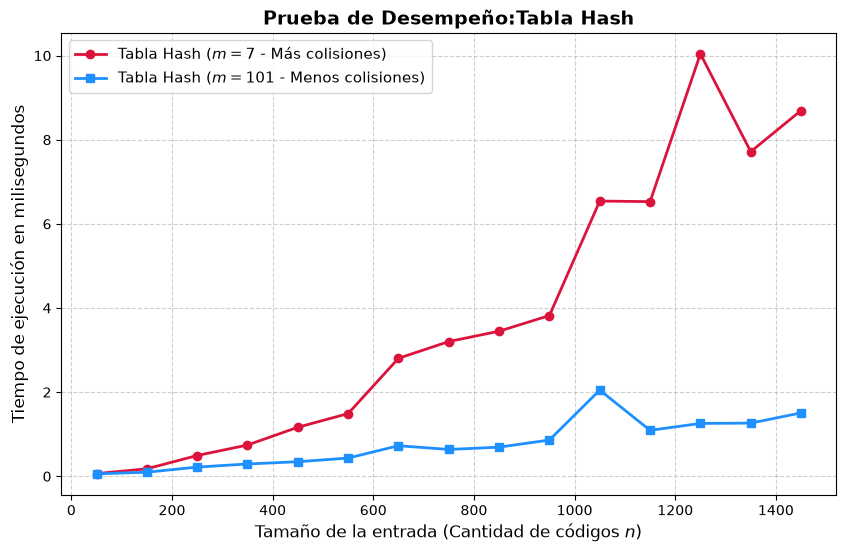

In [15]:
from random import randint
import time
import matplotlib.pyplot as plt

def bench_tabla_hash(n: int, step: int = 100) -> tuple[list, list]:
   
    resultados_m_pequeno = []  # m = 7 (Mayor tasa de colisiones)
    resultados_m_grande = []   # m = 101 (Menor tasa de colisiones)

    for size in range(50, n + 1, step):
        datos = [randint(1, 100000) for _ in range(size)]

        # --- 1. Medir tiempo con m pequeño (m = 7) ---
        m1 = 7
        tabla1 = [[] for _ in range(m1)]
        ti = time.perf_counter()
        for val in datos:
            indice = val % m1
            # Evitamos duplicados para mantener la consistencia de la prueba
            if not any(p["codigo"] == val for p in tabla1[indice]):
                tabla1[indice].append({"codigo": val, "nombre": f"Prod_{val}", "precio": 1000.0, "cantidad": 10})
        tf = time.perf_counter()
        delta_m7 = (tf - ti) * 1000
        resultados_m_pequeno.append((size, delta_m7))

        # --- 2. Medir tiempo con m grande (m = 101) ---
        m2 = 101
        tabla2 = [[] for _ in range(m2)]
        ti = time.perf_counter()
        for val in datos:
            indice = val % m2
            if not any(p["codigo"] == val for p in tabla2[indice]):
                tabla2[indice].append({"codigo": val, "nombre": f"Prod_{val}", "precio": 1000.0, "cantidad": 10})
        tf = time.perf_counter()
        delta_m101 = (tf - ti) * 1000
        resultados_m_grande.append((size, delta_m101))

        
    return resultados_m_pequeno, resultados_m_grande


def dibujar_comparativa_hash(res_m7, res_m101, dimensiones=(10, 6)):
    x_m7 = [size for size, timing in res_m7]
    y_m7 = [timing for size, timing in res_m7]

    x_m101 = [size for size, timing in res_m101]
    y_m101 = [timing for size, timing in res_m101]

    assert len(x_m7) == len(y_m7) and len(x_m101) == len(y_m101)

    plt.figure(figsize=dimensiones)
    plt.plot(x_m7, y_m7, label="Tabla Hash ($m = 7$ - Más colisiones)", color="crimson", linewidth=2, marker='o')
    plt.plot(x_m101, y_m101, label="Tabla Hash ($m = 101$ - Menos colisiones)", color="dodgerblue", linewidth=2, marker='s')

    plt.xlabel("Tamaño de la entrada (Cantidad de códigos $n$)", fontsize=12)
    plt.ylabel("Tiempo de ejecución en milisegundos", fontsize=12)
    plt.title("Prueba de Desempeño:Tabla Hash", fontsize=14, fontweight="bold")
    plt.legend(fontsize=11)
    plt.grid(True, linestyle="--", alpha=0.6)
    plt.show()


# ==========================================
# EJECUCIÓN DE LA PRUEBA DE DESEMPEÑO
# ==========================================
tiempos_m7, tiempos_m101 = bench_tabla_hash(1500, step=100)
dibujar_comparativa_hash(tiempos_m7, tiempos_m101)
